In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow:", tf.__version__)
print("NumPy:", np.__version__)

TensorFlow: 2.21.0
NumPy: 2.4.6


In [ ]:
from google.colab import files

uploaded = files.upload()

Saving Water Quality Dataset from Water Sources in Kenya.zip to Water Quality Dataset from Water Sources in Kenya.zip


In [ ]:
import zipfile
import os

# Obtener el nombre del ZIP cargado
zip_name = next(iter(uploaded))

# Crear carpeta para los datos
os.makedirs("dataset", exist_ok=True)

# Extraer contenido
with zipfile.ZipFile(zip_name, 'r') as zip_ref:
    zip_ref.extractall("dataset")

print("Archivos extraídos:")
for root, dirs, filenames in os.walk("dataset"):
    for filename in filenames:
        print(os.path.join(root, filename))

Archivos extraídos:
dataset/Water Quality Dataset from Water Sources in Kenya/water_quality_dataset1.csv
dataset/Water Quality Dataset from Water Sources in Kenya/processed_water_quality_dataset1.numbers


In [ ]:
import glob

csv_files = glob.glob("dataset/**/*.csv", recursive=True)

print("Archivos CSV encontrados:")

for file in csv_files:
    print(file)

Archivos CSV encontrados:
dataset/Water Quality Dataset from Water Sources in Kenya/water_quality_dataset1.csv


In [ ]:
# Seleccionamos el primer CSV encontrado
df = pd.read_csv(csv_files[0])

# Mostrar las primeras filas
display(df.head(10))

# Mostrar nombres de las columnas
print("\nColumnas del dataset:")
print(df.columns.tolist())

# Información general
print("\nInformación del dataset:")
df.info()

# Estadísticas
display(df.describe())

,pH,TDS_ppm,Turbidity_NTU,Temperature_C,Label
0,7.38,138.7,0.25,20.25,Safe
1,7.42,79.2,0.45,20.14,Safe
2,7.05,104.1,1.18,20.12,Safe
3,7.32,112.8,0.53,19.65,Safe
4,6.87,171.9,1.97,19.42,Safe
5,7.19,82.3,2.25,19.49,Safe
6,7.14,102.2,0.53,20.10,Safe
7,6.94,156.1,1.28,19.50,Safe
8,6.84,175.3,0.52,20.16,Safe
9,7.43,156.1,0.21,20.29,Safe



Columnas del dataset:
['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C', 'Label']

Información del dataset:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100800 entries, 0 to 100799
Data columns (total 5 columns):
 #   Column         Non-Null Count   Dtype  
---  ------         --------------   -----  
 0   pH             100800 non-null  float64
 1   TDS_ppm        100800 non-null  float64
 2   Turbidity_NTU  100800 non-null  float64
 3   Temperature_C  100800 non-null  float64
 4   Label          100800 non-null  object 
dtypes: float64(4), object(1)
memory usage: 3.8+ MB


,pH,TDS_ppm,Turbidity_NTU,Temperature_C
count,100800.000000,100800.000000,100800.000000,100800.000000
mean,7.593915,692.646992,11.306750,24.883516
std,0.799464,647.331906,9.868407,2.688138
min,6.090000,28.600000,0.000000,16.560000
25%,7.010000,163.000000,1.920000,23.090000
50%,7.380000,472.850000,9.970000,25.040000
75%,8.100000,1023.325000,18.540000,26.930000
max,9.960000,2806.100000,72.750000,31.510000


Distribución de las etiquetas:
Label
Unsafe    70560
Safe      30240
Name: count, dtype: int64

Porcentajes:
Label
Unsafe    70.0
Safe      30.0
Name: proportion, dtype: float64


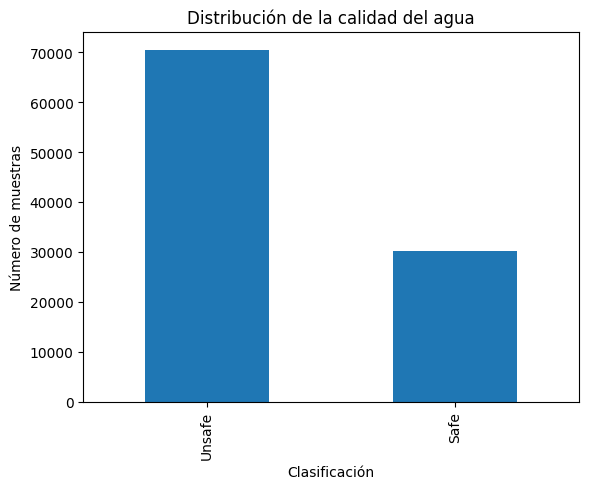

In [ ]:
# Contar las observaciones de cada categoría
print("Distribución de las etiquetas:")

print(df['Label'].value_counts())

# Mostrar porcentajes
print("\nPorcentajes:")

print(df['Label'].value_counts(normalize=True) * 100)

# Representar gráficamente
df['Label'].value_counts().plot(
    kind='bar',
    title='Distribución de la calidad del agua',
    xlabel='Clasificación',
    ylabel='Número de muestras'
)

plt.show()

In [ ]:
# Variables de entrada
X = df[
    ['pH', 'TDS_ppm', 'Turbidity_NTU', 'Temperature_C']
].values

# Variable objetivo
y = df['Label'].values

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Dimensiones de X: (100800, 4)
Dimensiones de y: (100800,)


In [ ]:
# Convertir las etiquetas a valores numéricos
y = (df['Label'] == 'Unsafe').astype(int).values

print("Etiquetas codificadas:")
print("Safe = 0")
print("Unsafe = 1")

print("\nPrimeras 10 etiquetas:")
print(y[:10])

Etiquetas codificadas:
Safe = 0
Unsafe = 1

Primeras 10 etiquetas:
[0 0 0 0 0 0 0 0 0 0]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Datos de entrenamiento:", X_train.shape)
print("Datos de prueba:", X_test.shape)

print("\nDistribución entrenamiento:")
print(np.bincount(y_train))

print("\nDistribución prueba:")
print(np.bincount(y_test))

Datos de entrenamiento: (80640, 4)
Datos de prueba: (20160, 4)

Distribución entrenamiento:
[24192 56448]

Distribución prueba:
[ 6048 14112]


In [ ]:
scaler = StandardScaler()

# Ajustar únicamente con los datos de entrenamiento
X_train = scaler.fit_transform(X_train)

# Aplicar la misma transformación al conjunto de prueba
X_test = scaler.transform(X_test)

print("Media de las variables normalizadas:")
print(X_train.mean(axis=0))

print("\nDesviación típica:")
print(X_train.std(axis=0))

Media de las variables normalizadas:
[-1.16198127e-13  5.42118296e-15 -5.52555273e-15  7.38905107e-14]

Desviación típica:
[1. 1. 1. 1.]


In [ ]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Crear el modelo
model = keras.Sequential([
    layers.Input(shape=(4,)),

    layers.Dense(16, activation='relu'),

    layers.Dense(8, activation='relu'),

    layers.Dense(1, activation='sigmoid')
])

# Configurar el entrenamiento
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy', tf.keras.metrics.Precision(), tf.keras.metrics.Recall()]
)

# Mostrar la estructura del modelo
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │            80 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225 (900.00 B)

 Trainable params: 225 (900.00 B)

 Non-trainable params: 0 (0.00 B)

In [ ]:
# Compensar el desequilibrio entre las clases
class_weights = {
    0: 1.67,
    1: 0.71
}

# Detener el entrenamiento cuando deje de mejorar
early_stopping = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=3,
    min_delta=0.001,
    restore_best_weights=True
)

# Entrenar la red neuronal
history = model.fit(
    X_train,
    y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    class_weight=class_weights,
    callbacks=[early_stopping],
    verbose=1
)

Epoch 1/50
2016/2016 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9806 - loss: 0.0664 - precision: 0.9965 - recall: 0.9758 - val_accuracy: 0.9996 - val_loss: 0.0035 - val_precision: 1.0000 - val_recall: 0.9994
Epoch 2/50
2016/2016 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9995 - loss: 0.0022 - precision: 1.0000 - recall: 0.9993 - val_accuracy: 0.9999 - val_loss: 0.0011 - val_precision: 1.0000 - val_recall: 0.9998
Epoch 3/50
2016/2016 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9997 - loss: 0.0010 - precision: 1.0000 - recall: 0.9996 - val_accuracy: 0.9999 - val_loss: 5.2366e-04 - val_precision: 1.0000 - val_recall: 0.9999
Epoch 4/50
2016/2016 ━━━━━━━━━━━━━━━━━━━━ 7s 3ms/step - accuracy: 0.9998 - loss: 7.6570e-04 - precision: 1.0000 - recall: 0.9997 - val_accuracy: 0.9994 - val_loss: 0.0016 - val_precision: 1.0000 - val_recall: 0.9991
Epoch 5/50
2016/2016 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9998 - loss: 6.1395e-04 - precision: 1.0000 - recall: 0.9997 - val_accuracy:

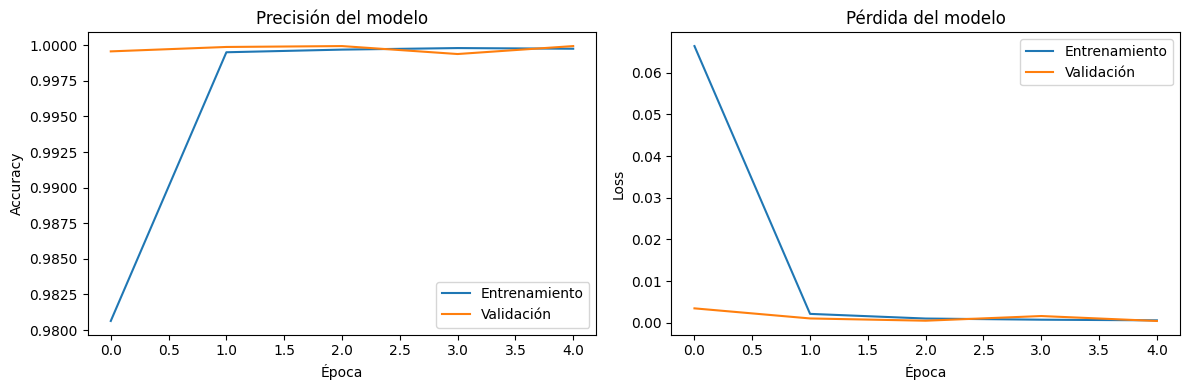

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Entrenamiento')
plt.plot(history.history['val_accuracy'], label='Validación')
plt.title('Precisión del modelo')
plt.xlabel('Época')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Entrenamiento')
plt.plot(history.history['val_loss'], label='Validación')
plt.title('Pérdida del modelo')
plt.xlabel('Época')
plt.ylabel('Loss')
plt.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Evaluar el modelo con los datos de prueba
results = model.evaluate(X_test, y_test, verbose=0)

print("Resultados de evaluación:")

for name, value in zip(model.metrics_names, results):
    print(f"{name}: {value:.4f}")

Resultados de evaluación:
loss: 0.0009
compile_metrics: 1.0000


In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

# Obtener predicciones
predictions = model.predict(X_test)

# Convertir probabilidades en etiquetas
y_pred = (predictions >= 0.5).astype(int).flatten()

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)

print("Matriz de confusión:")
print(cm)

# Informe de clasificación
print("\nInforme de clasificación:")
print(classification_report(
    y_test,
    y_pred,
    target_names=['Safe', 'Unsafe']
))

630/630 ━━━━━━━━━━━━━━━━━━━━ 1s 1ms/step
Matriz de confusión:
[[ 6048     0]
 [    1 14111]]

Informe de clasificación:
              precision    recall  f1-score   support

        Safe       1.00      1.00      1.00      6048
      Unsafe       1.00      1.00      1.00     14112

    accuracy                           1.00     20160
   macro avg       1.00      1.00      1.00     20160
weighted avg       1.00      1.00      1.00     20160



In [ ]:
for i in range(10):
    print(
        f"Real: {'Unsafe' if y_test[i] == 1 else 'Safe'} | "
        f"Probabilidad Unsafe: {predictions[i][0]:.4f}"
    )

Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Safe | Probabilidad Unsafe: 0.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 0.9998
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000
Real: Unsafe | Probabilidad Unsafe: 1.0000


In [ ]:
import numpy as np

# Guardar parámetros de normalización
normalization_mean = scaler.mean_.astype(np.float32)
normalization_scale = scaler.scale_.astype(np.float32)

print("Media:")
print(normalization_mean)

print("\nDesviación típica:")
print(normalization_scale)

Media:
[  7.59801  694.95135   11.303397  24.88812 ]

Desviación típica:
[  0.8006336 649.285       9.859641    2.6876209]


In [ ]:
# Crear el conversor
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Activar optimización
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Datos representativos para la cuantización
def representative_dataset():
    for i in range(1000):
        yield [X_train[i:i+1].astype(np.float32)]

converter.representative_dataset = representative_dataset

# Utilizar operaciones INT8
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Entrada y salida INT8
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convertir modelo
tflite_model = converter.convert()

print("Modelo convertido correctamente.")
print("Tamaño:", len(tflite_model), "bytes")

Saved artifact at '/tmp/tmp_gdn62g2'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 4), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  134227673615824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675164176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675165712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675166096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675158032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675165904: TensorSpec(shape=(), dtype=tf.resource, name=None)


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


Modelo convertido correctamente.
Tamaño: 3368 bytes


In [ ]:
# Crear intérprete
interpreter = tf.lite.Interpreter(model_content=tflite_model)

# Preparar memoria
interpreter.allocate_tensors()

# Obtener información de entrada y salida
input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

print("Entrada:")
print(input_details)

print("\nSalida:")
print(output_details)

Entrada:
[{'name': 'serving_default_keras_tensor:0', 'index': 0, 'shape': array([1, 4], dtype=int32), 'shape_signature': array([-1,  4], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.02743510529398918, -23), 'quantization_parameters': {'scales': array([0.02743511], dtype=float32), 'zero_points': array([-23], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]

Salida:
[{'name': 'StatefulPartitionedCall_1:0', 'index': 10, 'shape': array([1, 1], dtype=int32), 'shape_signature': array([-1,  1], dtype=int32), 'dtype': <class 'numpy.int8'>, 'quantization': (0.00390625, -128), 'quantization_parameters': {'scales': array([0.00390625], dtype=float32), 'zero_points': array([-128], dtype=int32), 'quantized_dimension': 0, 'block_size': 0}, 'sparsity_parameters': {}}]


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
# Seleccionar una muestra de prueba
sample = X_test[0:1].astype(np.float32)

# Predicción con Keras
keras_prediction = model.predict(sample, verbose=0)[0][0]

# Obtener parámetros de cuantización
input_scale, input_zero_point = input_details[0]['quantization']
output_scale, output_zero_point = output_details[0]['quantization']

# Cuantizar la entrada
quantized_input = np.round(
    sample / input_scale + input_zero_point
).clip(-128, 127).astype(np.int8)

# Ejecutar TensorFlow Lite
interpreter.set_tensor(
    input_details[0]['index'],
    quantized_input
)

interpreter.invoke()

# Obtener y deshacer la cuantización de la salida
quantized_output = interpreter.get_tensor(
    output_details[0]['index']
)

tflite_prediction = (
    quantized_output.astype(np.float32) - output_zero_point
) * output_scale

print("Predicción Keras:", keras_prediction)
print("Predicción TensorFlow Lite:", tflite_prediction[0][0])

Predicción Keras: 1.0
Predicción TensorFlow Lite: 0.99609375


In [ ]:
import os

print("Archivos disponibles en Colab:\n")

for archivo in os.listdir("/content"):
    print(archivo)

Archivos disponibles en Colab:

.config
Water Quality Dataset from Water Sources in Kenya.zip
dataset
sample_data


In [ ]:
print("Modelo entrenado:", "model" in globals())
print("Normalizador:", "scaler" in globals())
print("Datos de entrenamiento:", "X_train" in globals())
print("Etiquetas:", "y_train" in globals())

Modelo entrenado: True
Normalizador: True
Datos de entrenamiento: True
Etiquetas: True


In [ ]:
import tensorflow as tf
import numpy as np

# Convertir el modelo Keras a TensorFlow Lite
converter = tf.lite.TFLiteConverter.from_keras_model(model)

# Optimización y cuantización INT8
converter.optimizations = [tf.lite.Optimize.DEFAULT]

# Dataset representativo para la cuantización
def representative_dataset():
    for i in range(1000):
        yield [X_train[i:i+1].astype(np.float32)]

converter.representative_dataset = representative_dataset

# Forzar operaciones INT8
converter.target_spec.supported_ops = [
    tf.lite.OpsSet.TFLITE_BUILTINS_INT8
]

# Entradas y salidas INT8
converter.inference_input_type = tf.int8
converter.inference_output_type = tf.int8

# Convertir
tflite_model = converter.convert()

# Guardar modelo
with open("water_quality_model.tflite", "wb") as f:
    f.write(tflite_model)

print("Modelo convertido correctamente")
print("Tamaño:", len(tflite_model), "bytes")

Saved artifact at '/tmp/tmp8btl7mge'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 4), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 1), dtype=tf.float32, name=None)
Captures:
  134227673615824: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675164176: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675165712: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675166096: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675158032: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134227675165904: TensorSpec(shape=(), dtype=tf.resource, name=None)
Modelo convertido correctamente
Tamaño: 3368 bytes


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/convert.py:846: UserWarning: Statistics for quantized inputs were expected, but not specified; continuing anyway.
  warnings.warn(


In [ ]:
# Generar el array de bytes del modelo

with open("water_quality_model.h", "w") as f:
    f.write("#pragma once\n")
    f.write("#include <stdint.h>\n\n")
    f.write("alignas(16) const unsigned char water_quality_model[] = {\n")

    for i, byte in enumerate(tflite_model):
        if i % 12 == 0:
            f.write("    ")
        f.write(f"0x{byte:02x}, ")
        if i % 12 == 11:
            f.write("\n")

    f.write("\n};\n")
    f.write(f"const unsigned int water_quality_model_len = {len(tflite_model)};\n")

print("Archivo water_quality_model.h generado")

Archivo water_quality_model.h generado


In [ ]:
# Parámetros de normalización
normalization_mean = scaler.mean_
normalization_scale = scaler.scale_

# Parámetros de cuantización del modelo
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()

input_details = interpreter.get_input_details()
output_details = interpreter.get_output_details()

input_scale, input_zero_point = input_details[0]["quantization"]
output_scale, output_zero_point = output_details[0]["quantization"]

# Generar archivo header
with open("water_quality_scaler.h", "w") as f:
    f.write("#pragma once\n\n")

    f.write("const float normalization_mean[4] = {")
    f.write(", ".join(f"{x:.8f}f" for x in normalization_mean))
    f.write("};\n\n")

    f.write("const float normalization_scale[4] = {")
    f.write(", ".join(f"{x:.8f}f" for x in normalization_scale))
    f.write("};\n\n")

    f.write(f"const float input_quantization_scale = {input_scale:.12f}f;\n")
    f.write(f"const int input_quantization_zero_point = {input_zero_point};\n")
    f.write(f"const float output_quantization_scale = {output_scale:.12f}f;\n")
    f.write(f"const int output_quantization_zero_point = {output_zero_point};\n")

print("Archivo water_quality_scaler.h generado")

Archivo water_quality_scaler.h generado


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


In [ ]:
from google.colab import files

for archivo in [
    "water_quality_model.h",
    "water_quality_scaler.h",
    "water_quality_model.tflite"
]:
    files.download(archivo)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>